In [10]:
import pandas as pd
df= pd.read_csv("used_cars (2).csv")
df.head()

,car_id,brand,year,km_driven,fuel,transmission,owners,price_lakh
0,C058,Maruti,2019,86297.0,Petrol,Manual,2,4.40
1,C060,Hyundai,2025,13016.0,Diesel,Manual,1,11.39
2,C092,Honda,2018,54910.0,Diesel,Automatic,2,10.45
3,C102,Hyundai,2018,67325.0,Hybrid,Manual,2,8.67
4,C018,Hyundai,2014,99872.0,Petrol,Manual,1,5.70


In [12]:
print(df.shape)
df.info()

(124, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 124 entries, 0 to 123
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   car_id        124 non-null    object 
 1   brand         124 non-null    object 
 2   year          124 non-null    int64  
 3   km_driven     118 non-null    float64
 4   fuel          124 non-null    object 
 5   transmission  124 non-null    object 
 6   owners        124 non-null    int64  
 7   price_lakh    124 non-null    float64
dtypes: float64(2), int64(2), object(4)
memory usage: 7.9+ KB


In [13]:
print(df.isnull().sum())
print(df.duplicated().sum())
print(list(df['fuel'].unique()))
print(list(df['transmission'].unique()))

car_id          0
brand           0
year            0
km_driven       6
fuel            0
transmission    0
owners          0
price_lakh      0
dtype: int64
4
['Petrol', 'Diesel', 'Hybrid', 'diesel', 'petrol', 'HYBRID', 'PETROL', 'DIESEL']
['Manual', 'Automatic', 'automatic', 'manual']


In [14]:
df['km_driven'] = df['km_driven'].fillna(df['km_driven'].median())
df = df.drop_duplicates()
df['fuel'] = df['fuel'].str.title()
df['transmission'] = df['transmission'].str.title()
print(df.isnull().sum().sum(), df.duplicated().sum(), df.shape)
print(list(df['fuel'].unique()))

0 0 (120, 8)
['Petrol', 'Diesel', 'Hybrid']


In [15]:
df['car_age'] = 2026 - df['year']
df['km_thousand'] = df['km_driven'] / 1000
df = df.drop(['car_id', 'year', 'km_driven'], axis=1)
print(df.head(3))

     brand    fuel transmission  owners  price_lakh  car_age  km_thousand
0   Maruti  Petrol       Manual       2        4.40        7       86.297
1  Hyundai  Diesel       Manual       1       11.39        1       13.016
2    Honda  Diesel    Automatic       2       10.45        8       54.910


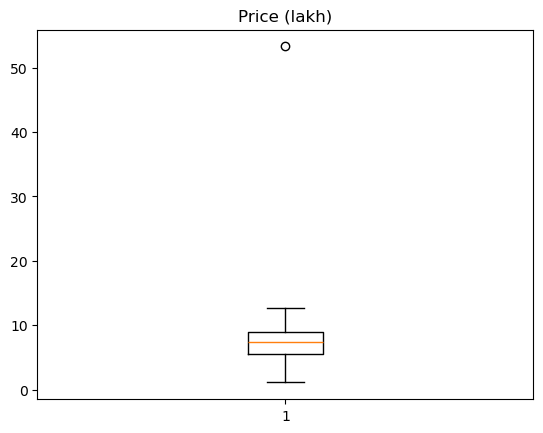

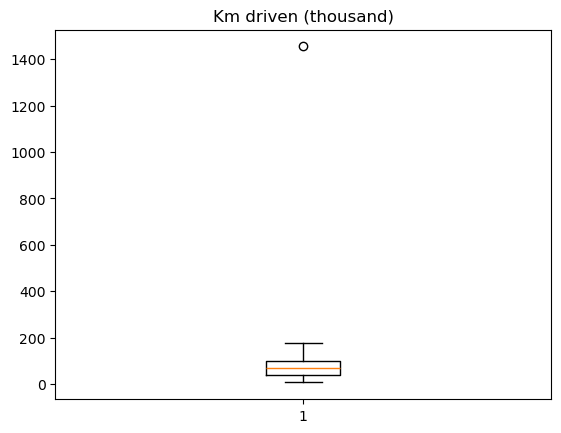

In [16]:
import matplotlib.pyplot as plt
plt.boxplot(df['price_lakh'])
plt.title('Price (lakh)')
plt.show()
plt.boxplot(df['km_thousand'])
plt.title('Km driven (thousand)')
plt.show()

In [17]:
q1 = df['price_lakh'].quantile(0.25)
q3 = df['price_lakh'].quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr
print(round(q1, 2), round(q3, 2), round(iqr, 2), round(low, 2), round(high, 2))
print(df[(df['price_lakh'] < low) | (df['price_lakh'] > high)])
df = df[(df['price_lakh'] >= low) & (df['price_lakh'] <= high)]
print(df.shape)

5.56 8.94 3.39 0.48 14.03
    brand    fuel transmission  owners  price_lakh  car_age  km_thousand
9  Maruti  Petrol    Automatic       1        53.3       11       93.605
(119, 7)


In [18]:
q1 = df['km_thousand'].quantile(0.25)
q3 = df['km_thousand'].quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr
print(round(q1, 2), round(q3, 2), round(iqr, 2), round(low, 2), round(high, 2))
print(df[(df['km_thousand'] < low) | (df['km_thousand'] > high)])
df = df[(df['km_thousand'] >= low) & (df['km_thousand'] <= high)]
print(df.shape)

38.01 98.45 60.44 -52.66 189.11
     brand    fuel transmission  owners  price_lakh  car_age  km_thousand
66  Maruti  Hybrid       Manual       1        4.95       13      1454.79
(118, 7)


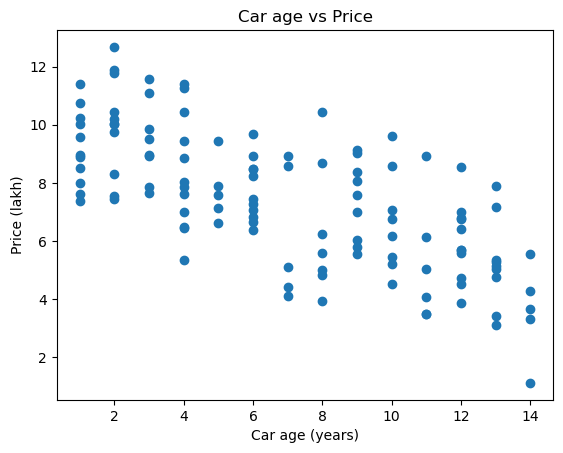

In [19]:
# Scatter plot of car age (years) and price
plt.scatter(df['car_age'], df['price_lakh'])
plt.title('Car age vs Price')
plt.xlabel('Car age (years)')
plt.ylabel('Price (lakh)')
plt.show()

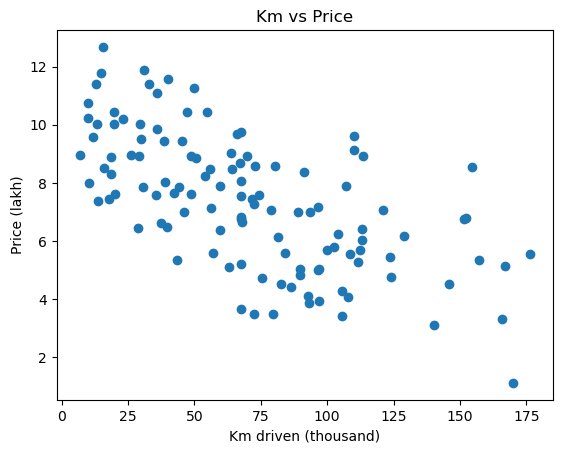

In [20]:
# Scatter plot of km driven (thousand) and price
plt.scatter(df['km_thousand'], df['price_lakh'])
plt.title('Km vs Price')
plt.xlabel('Km driven (thousand)')
plt.ylabel('Price (lakh)')
plt.show()

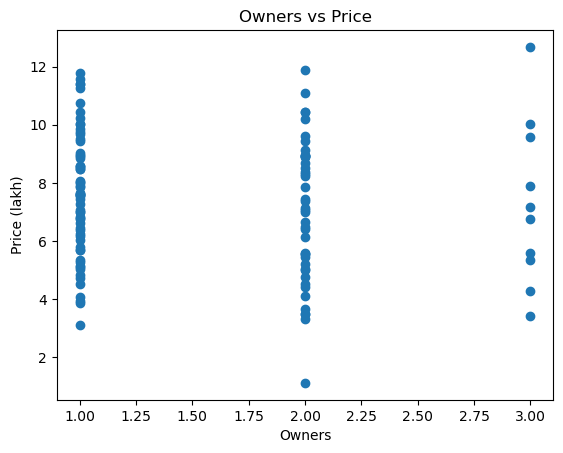

In [21]:
# Scatter plot of owners and price
plt.scatter(df['owners'], df['price_lakh'])
plt.title('Owners vs Price')
plt.xlabel('Owners')
plt.ylabel('Price (lakh)')
plt.show()

In [22]:
df = pd.get_dummies(df, columns=['brand', 'fuel', 'transmission'], drop_first=True, dtype=int)
print(df.columns.tolist())
print(df.head(3))

['owners', 'price_lakh', 'car_age', 'km_thousand', 'brand_Hyundai', 'brand_Maruti', 'fuel_Hybrid', 'fuel_Petrol', 'transmission_Manual']
   owners  price_lakh  car_age  km_thousand  brand_Hyundai  brand_Maruti  \
0       2        4.40        7       86.297              0             1   
1       1       11.39        1       13.016              1             0   
2       2       10.45        8       54.910              0             0   

   fuel_Hybrid  fuel_Petrol  transmission_Manual  
0            0            1                    1  
1            0            0                    1  
2            0            0                    0  


In [23]:
# X holds all columns except the target
X = df.drop('price_lakh', axis=1)
y = df['price_lakh']
print(X.shape, y.shape)

(118, 8) (118,)


In [24]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(94, 8) (24, 8)


In [25]:
# Import LinearRegression
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)
print(round(model.intercept_, 2))
print(pd.Series(model.coef_, index=X.columns).round(3))

14.76
owners                -0.455
car_age               -0.359
km_thousand           -0.011
brand_Hyundai         -1.625
brand_Maruti          -3.193
fuel_Hybrid            0.887
fuel_Petrol           -1.218
transmission_Manual   -1.289
dtype: float64


In [26]:
# Predict prices for the test cars
y_pred = model.predict(X_test)
result = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred.round(2)})
result['Error'] = (result['Actual'] - result['Predicted']).round(2)
print(result.head())

    Actual  Predicted  Error
57    8.00       8.14  -0.14
92    8.87       9.41  -0.54
4     5.70       4.78   0.92
46    7.84       8.77  -0.93
27    3.42       3.17   0.25


In [27]:
# Import the metrics
from sklearn.metrics import mean_absolute_error, r2_score
print('MAE:', round(mean_absolute_error(y_test, y_pred), 2))
print('Average price:', round(y.mean(), 2))
print('Test R2:', round(r2_score(y_test, y_pred), 3))
print('Train R2:', round(model.score(X_train, y_train), 3))

MAE: 0.36
Average price: 7.36
Test R2: 0.952
Train R2: 0.971


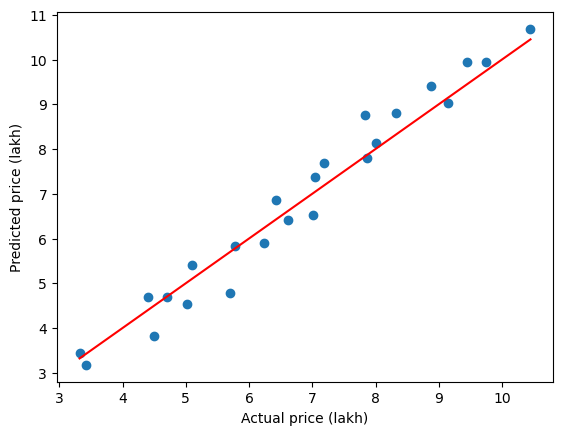

In [28]:
# Plot actual price on x axis and predicted price on y axis
plt.scatter(y_test, y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')
plt.xlabel('Actual price (lakh)')
plt.ylabel('Predicted price (lakh)')
plt.show()

In [29]:
# Details of one new car: 5 years old, 40 thousand km, 1 owner, Hyundai, Petrol, Manual
new_car = pd.DataFrame([{'owners': 1, 'car_age': 5, 'km_thousand': 40, 'brand_Hyundai': 1, 'brand_Maruti': 0, 'fuel_Hybrid': 0, 'fuel_Petrol': 1, 'transmission_Manual': 1}])
new_car = new_car[X.columns]
print('Suggested price:', round(model.predict(new_car)[0], 2), 'lakh')

Suggested price: 7.95 lakh
